# 19 · Define an inspectable S(A,B)

A pair of grayscale images yields six named agreements. The comparison uses images alone. Ground-truth arrangement labels enter only the benchmark. Every gallery shares a motif inventory, so the global orientation histogram cannot distinguish its candidates.

All six agreements are symmetric in the tested example. The equal-inventory gallery makes the orientation-histogram score identical across its four candidates.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage5 import (COMPONENTS, CONDITIONS, SPLITS, make_images, similarity_profile,
                                weighted_similarity, run, paired_interval, explain)
OUT=ROOT/'results'/'stage5'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## Fix the observation and relevance rules
Every image uses a known 8 × 8 tile grid. An arrangement is a balanced assignment of two orientations to the 64 sites. A query depicts one of four gallery arrangements, modulo integer tile translations. The three distractors swap 2, 6 or 12 pairs of differently oriented sites. Tile contrast reversals and local motif changes preserve the target. Occlusion and noise remove evidence without changing the target ID.

Six arrangement generators are split by family. The training groups are independent and compact. The development group is diagonal. Elongated, checker-biased and separable arrangements are held out entirely. The construction rejects duplicate candidate arrangements up to cyclic translation across all groups and splits. Each generator supplies 32 galleries.

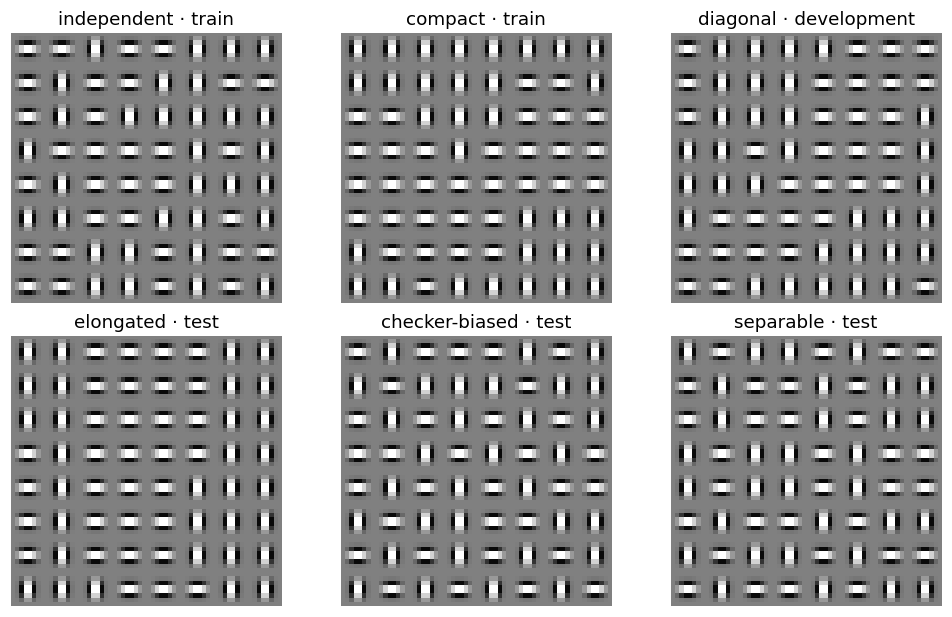

In [3]:
examples={}
for key,query,references,truth in make_images():
    if key[2:]==(0,'wave'):
        examples[key[1]]=(key,query,references,truth)
fig,axes=plt.subplots(2,3,figsize=(9,5.5))
for ax,(family,(_,_,refs,truth)) in zip(axes.flat,examples.items()):
    limit=np.max(np.abs(refs[truth]))
    ax.imshow(refs[truth],cmap='gray',vmin=-limit,vmax=limit)
    split=next(s for s,fs in SPLITS.items() if family in fs)
    ax.set_title(f'{family} · {split}');ax.set_axis_off()
show('19_arrangement_families')

## Separate the observable from the decision
For each coordinate $j$, compute a bounded relative distance $d_j$ and report $S_j=1-d_j$. The profile exposes agreement in local orientation counts, pair organization, triplet organization, aligned orientations, intensity power and sign-aware aligned pixels.

A supplied simplex vector gives a scalar score $s_w=\sum_j w_j S_j$. A weight represents how a decision combines the declared units. The observable values and their interpretations remain available independently of the weight.

In [5]:
_,query,refs,truth=examples['separable']
a,b=query,refs[truth]
ab=similarity_profile(a,b)
ba=similarity_profile(b,a)
np.testing.assert_allclose(ab,ba,atol=2e-8)
np.testing.assert_allclose(similarity_profile(a,a),1,atol=2e-8)
assert ((ab>=0)&(ab<=1+1e-8)).all()
weights=np.full(len(COMPONENTS),1/len(COMPONENTS))
card=weighted_similarity(ab,weights)
display(card.round(5))
print('Equal-weight scalar score:',card.contribution.sum())
gallery=pd.DataFrame([similarity_profile(query,r) for r in refs])
display(gallery.round(3))
assert np.ptp(gallery['orientation histogram'])<1e-10

,agreement,weight,contribution
orientation histogram,1.00000,0.16667,0.16667
orientation pairs,1.00000,0.16667,0.16667
orientation triplets,1.00000,0.16667,0.16667
aligned orientation,1.00000,0.16667,0.16667
intensity power,0.23902,0.16667,0.03984
aligned sign-free pixels,1.00000,0.16667,0.16667


Equal-weight scalar score: 0.8731699041150505


,orientation histogram,orientation pairs,orientation triplets,aligned orientation,intensity power,aligned sign-free pixels
agreement,1.0,0.432,0.0,0.414,0.233,0.597
agreement,1.0,0.801,0.0,0.750,0.236,0.828
agreement,1.0,0.551,0.0,0.567,0.240,0.702
agreement,1.0,1.000,1.0,1.000,0.239,1.000


## Bridge to ordinary images
The pair API accepts two finite 64 × 64 grayscale arrays. The tile and torus conventions make it a controlled prototype. Standard datasets require explicit choices for resizing, boundaries, foreground/background and allowed alignment. The orientation histogram can become informative when gallery candidates have different inventories. In this experiment equal inventory deliberately neutralizes it.